# Replicating the Typing37K study

Mike Deng · STAT 5200

I wanted to see which numbers in Palin et al. (2019) I could get from the files the authors released. The original study asked people to type 15 English sentences on their own mobile devices. I used Aalto’s processed participant data to redo the full-sample comparisons in Tables 3–6. The release has one row per participant with measures such as words per minute (WPM) already calculated. The fields needed to recreate the paper’s U.S. subsample are absent from this release.

[Paper](https://www.pokristensson.com/pubs/PalinEtAlMobileHCI2019.pdf) · [Aalto data release](https://userinterfaces.aalto.fi/typing37k/) · [Statistical supplement](https://userinterfaces.aalto.fi/typing37k/resources/supplement.pdf)

## 1. Check the data and count the exclusions

I started with the two files listed below. The loader uses the local copies if both are present. A fresh checkout downloads those two members from Aalto’s ZIP. The SHA-256 values identify the exact files used in this run. The code checks both against the pinned release and checks that each retained participant has a unique ID.

To rerun, open this notebook from the repository root in a Python 3.12 Jupyter kernel with the packages from `requirements.txt` installed. Use **Run All**. [Data files and parsing notes](data/README.md) · [Authors’ analysis notebook](https://userinterfaces.aalto.fi/typing37k/resources/python_analysis.ipynb)

In [1]:
"""Full-sample participant-level replication of Palin et al. (2019)."""

from itertools import combinations
from pathlib import Path

import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests


AGE_BANDS = ("0-9", "10-19", "20-29", "30-39", "40-49", "50-59", "60-69")
POSTURES = {
    "both_hands;thumbs": "Both thumbs",
    "both_hands;index_fingers": "Both index fingers",
    "right_hand;thumbs": "Right thumb",
    "right_hand;index_fingers": "Right index finger",
    "left_hand;thumbs": "Left thumb",
    "left_hand;index_fingers": "Left index finger",
}
ENGLISH = ("native", "always", "usually", "sometimes", "rarely", "never")
ITE_COLUMNS = {"P": "ITE_PREDICT", "A": "ITE_AUTOCORR", "G": "ITE_SWYPE"}

# Published full-sample values from Tables 3–6, in table order.
PERFORMANCE = {
    "WPM": ("Words per minute", 36.17, 13.22),
    "ERROR_RATE": ("Uncorrected error (%)", 2.34, 2.08),
    "P_KSPC": ("Keystrokes per character", 1.18, 0.18),
    "P_BSP": ("Backspaces per sentence", 1.89, 1.96),
}
DEMOGRAPHIC_GROUPS = {
    "gender": ("GENDER", ("female", "male"), ((36.0, 12.5), (36.1, 14.4))),
    "age": (
        "AGE_BAND",
        AGE_BANDS,
        (None, (39.6, 14.3), (36.5, 12.6), (32.2, 10.8),
         (28.9, 9.2), (26.3, 9.9), None),
    ),
    "english_experience": (
        "TYPE_ENGLISH",
        ENGLISH,
        ((37.8, 13.6), (35.9, 13.1), (34.5, 11.8),
         (30.4, 10.5), (29.6, 11.2), (25.6, 12.4)),
    ),
    "typing_course": ("HAS_TAKEN_TYPING_COURSE", (0, 1), ((36.4, 13.1), (35.7, 13.4))),
    "finger_count": ("NUM_FINGERS", (2, 1), ((37.7, 13.2), (29.2, 10.7))),
    "posture": (
        "HAND_FINGER",
        tuple(POSTURES),
        ((38.0, 13.1), (32.6, 12.7), (30.2, 10.5),
         (26.7, 9.7), (30.8, 12.4), (25.0, 11.4)),
    ),
}
ITE_GROUPS = {
    "none": (34.8, 12.6, 2.3, 1.2),
    "P": (32.8, 12.1, 2.3, 1.2),
    "A": (43.4, 14.4, 2.4, 1.2),
    "G": (32.2, 13.4, 2.4, 1.0),
    "P+A": (35.7, 12.6, 2.4, 1.2),
    "P+G": (31.5, 13.6, 2.2, 0.9),
    "A+G": (33.8, 12.1, 2.4, 1.1),
    "P+A+G": (28.8, 11.3, 2.4, 1.1),
}
ITE_CORRELATIONS = {
    "WPM": {"G": -0.003, "A": 0.237, "P": -0.183},
    "ERROR_RATE": {"G": -0.012, "A": 0.086, "P": -0.037},
    "P_KSPC": {"G": -0.251, "A": 0.181, "P": -0.232},
}
SUPPLEMENT_H = {
    "gender": 8.8426,
    "age": 2828.3453,
    "english_experience": 1364.9895,
    "posture": 2204.22245,
    "ite": 2288.61814,
}
BLUE = "#275f84"
TEAL = "#157d75"
AMBER = "#b65a25"
INK = "#142e43"

In [2]:
from hashlib import sha256
import platform
import sys
from tempfile import TemporaryDirectory

from IPython.display import Image, display

root = Path.cwd()
if not (root / "typing37k" / "data.py").is_file():
    # Find the Desktop checkout when opening the downloaded notebook on this Mac.
    root = Path.home() / "Desktop" / "typing37k-replication"
if not (root / "typing37k" / "data.py").is_file():
    raise FileNotFoundError("Open the notebook from the Typing37K repository root.")
sys.path.insert(0, str(root))

from typing37k.data import MEMBERS, SHA256, load_data

raw_dir = root / "data" / "raw"
cache_ready = all((raw_dir / name).is_file() for name in MEMBERS)
participants, sample_audit = load_data(raw_dir, offline=cache_ready)

files_used = []
for name in MEMBERS:
    path = raw_dir / name
    digest = sha256(path.read_bytes()).hexdigest()
    assert digest == SHA256[name], name
    files_used.append({"Aalto file": name, "Bytes": path.stat().st_size, "SHA-256": digest})

print(f"Python {platform.python_version()}")
print(f"Source: {'verified local Aalto files' if cache_ready else 'official Aalto download'}")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(files_used))

Python 3.12.4
Source: verified local Aalto files


,Aalto file,Bytes,SHA-256
0,open_participants.csv,16728580,26c1abdc46c1f98121b1189969e084a73f9d10228c69e0c8035a4290e82e74ba
1,open_participants_header.csv,886,79d7b717343ad61287c36c702998de22dd1f6385e9dc39a9d4da6366acbe87a4


In [3]:
released_n = int(sample_audit.iloc[0]["remaining"])
removed_n = int(sample_audit["removed"].sum())
assert participants["PARTICIPANT_ID"].is_unique
assert released_n - removed_n == len(participants) == 37_370

print(f"{released_n:,} released rows - {removed_n:,} exclusions = {len(participants):,} participants")
display(sample_audit.rename(columns={"step": "Cleaning step", "removed": "Removed", "remaining": "Remaining"}))

37,606 released rows - 236 exclusions = 37,370 participants


,Cleaning step,Removed,Remaining
0,source,0,37606
1,wpm_outliers,0,37606
2,error_rate_outliers,0,37606
3,unspecified_posture,176,37430
4,missing_device,0,37430
5,desktop_device,0,37430
6,incomplete_hand_finger,52,37378
7,invalid_typing_hours,8,37370


The biggest cut was 176 rows with unspecified typing posture. Another 52 had an incomplete hand or finger response, and eight had a numerical daily typing time outside 0–24 hours. I counted the exclusions in order, so a row that failed more than one check only counted once. [Cleaning code](typing37k/data.py)

## 2. Overall typing performance (Table 3)

I gave each participant one observation. For each measure I calculated the mean and sample standard deviation across participants. I copied the published benchmarks into the constants above so the table can show where the data and paper agree.

In [4]:
def _summarize(values: pd.Series) -> dict:
    return {
        "n": values.count(),
        "mean": values.mean(),
        "sd": values.std(),
        "min": values.min(),
        "p25": values.quantile(0.25),
        "median": values.median(),
        "p75": values.quantile(0.75),
        "max": values.max(),
    }

In [5]:
performance_rows = []
for column, (label, paper_mean, paper_sd) in PERFORMANCE.items():
    result = _summarize(participants[column])
    performance_rows.append({
        "Measure": label,
        "Participants": result["n"],
        "Computed mean": result["mean"],
        "Paper mean": paper_mean,
        "Computed SD": result["sd"],
        "Paper SD": paper_sd,
    })

table_3 = pd.DataFrame(performance_rows)
assert table_3["Computed mean"].round(2).equals(table_3["Paper mean"])
assert table_3["Computed SD"].round(2).equals(table_3["Paper SD"])
display(table_3.round(2))

,Measure,Participants,Computed mean,Paper mean,Computed SD,Paper SD
0,Words per minute,37370,36.17,36.17,13.22,13.22
1,Uncorrected error (%),37370,2.34,2.34,2.08,2.08
2,Keystrokes per character,37370,1.18,1.18,0.18,0.18
3,Backspaces per sentence,37370,1.89,1.89,1.96,1.96


The average speed was **36.17 WPM** and the mean uncorrected error rate was **2.34%**. Keystrokes per character and backspaces per sentence also match the paper at two decimal places. [Table 3 in the paper](https://www.pokristensson.com/pubs/PalinEtAlMobileHCI2019.pdf)

## 3. Typing speed by age and posture (Table 4)

I calculated group means and standard deviations, then used Kruskal–Wallis to compare the distributions. For pairs I used two-sided Mann–Whitney tests and applied the standard Holm adjustment within each set of comparisons. The authors’ notebook uses a different adjustment formula. I also report Cohen’s *d*, the difference in means divided by the pooled standard deviation, to show how large a difference is.

The paper’s age table prints five age bands. The supplement uses seven for the overall test, so I kept all seven in that test. [Paper](https://www.pokristensson.com/pubs/PalinEtAlMobileHCI2019.pdf) · [Statistical supplement](https://userinterfaces.aalto.fi/typing37k/resources/supplement.pdf)

In [6]:
def _cohen_d(first: np.ndarray, second: np.ndarray) -> float:
    """Signed mean difference divided by the pooled sample SD."""
    df = len(first) + len(second) - 2
    sum_squares = ((first - first.mean()) ** 2).sum() + ((second - second.mean()) ** 2).sum()
    pooled_sd = np.sqrt(sum_squares / df)
    return (first.mean() - second.mean()) / pooled_sd if pooled_sd else np.nan


def _comparison_tests(families: dict[str, dict]) -> tuple[pd.DataFrame, pd.DataFrame]:
    omnibus = []
    pairwise = []
    for family, groups in families.items():
        available = {name: sample for name, sample in groups.items() if len(sample)}
        if len(available) < 2:
            continue

        kw = stats.kruskal(*available.values())
        omnibus.append({
            "family": family,
            "method": "Kruskal–Wallis",
            "n": sum(map(len, available.values())),
            "groups": len(available),
            "df": len(available) - 1,
            "statistic_h": kw.statistic,
            "p_value": kw.pvalue,
            "supplement_h": SUPPLEMENT_H.get(family),
            "group_levels": " | ".join(map(str, available)),
        })
        comparisons = []
        for (name_a, sample_a), (name_b, sample_b) in combinations(available.items(), 2):
            mw = stats.mannwhitneyu(sample_a, sample_b, alternative="two-sided", method="asymptotic")
            comparisons.append({
                "family": family,
                "group_a": name_a,
                "group_b": name_b,
                "n_a": len(sample_a),
                "n_b": len(sample_b),
                "u_a": mw.statistic,
                "mean_diff_a_minus_b": sample_a.mean() - sample_b.mean(),
                "cohen_d_a_minus_b": _cohen_d(sample_a, sample_b),
                "p_raw": mw.pvalue,
            })
        adjusted = multipletests([row["p_raw"] for row in comparisons], method="holm")[1]
        for row, p_holm in zip(comparisons, adjusted):
            row["p_holm"] = p_holm
            row["reject_5pct"] = p_holm < 0.05
            pairwise.append(row)
    return pd.DataFrame(omnibus), pd.DataFrame(pairwise)


def _demographics(data: pd.DataFrame) -> tuple[pd.DataFrame, dict[str, dict]]:
    rows = []
    families = {}
    for family, (column, levels, benchmarks) in DEMOGRAPHIC_GROUPS.items():
        groups = {}
        for level, paper in zip(levels, benchmarks):
            sample = data.loc[data[column].eq(level), "WPM"].dropna()
            groups[level] = sample.to_numpy()
            paper_mean, paper_sd = paper or (np.nan, np.nan)
            label = POSTURES.get(level, level)
            if family == "typing_course":
                label = "yes" if level else "no"
            rows.append({
                "factor": family,
                "level": level,
                "label": label,
                "shown_in_paper_table_4": paper is not None,
                "n": len(sample),
                "percent_full_sample": 100 * len(sample) / len(data),
                "mean_wpm": sample.mean(),
                "sd_wpm": sample.std(),
                "paper_mean_wpm": paper_mean,
                "paper_sd_wpm": paper_sd,
                "mean_minus_paper": sample.mean() - paper_mean,
                "sd_minus_paper": sample.std() - paper_sd,
            })
        families[family] = groups
    return pd.DataFrame(rows), families

In [7]:
demographics, families = _demographics(participants)
omnibus, pairwise = _comparison_tests(families)

shown = demographics.loc[demographics["shown_in_paper_table_4"], [
    "factor", "label", "n", "mean_wpm", "paper_mean_wpm", "sd_wpm", "paper_sd_wpm",
]]
display(shown.reset_index(drop=True).round(2))

age_and_posture = omnibus.loc[omnibus["family"].isin(["age", "posture"]), [
    "family", "n", "groups", "statistic_h", "supplement_h",
]]
np.testing.assert_allclose(
    age_and_posture["statistic_h"], age_and_posture["supplement_h"], rtol=0, atol=0.0001,
)
display(age_and_posture.reset_index(drop=True).round(5))

oldest_pair = pairwise.loc[
    pairwise["family"].eq("age") & pairwise["group_a"].eq("50-59") & pairwise["group_b"].eq("60-69")
].iloc[0]
print(f"Example pairwise result, ages 50–59 versus 60–69: Holm p = {oldest_pair['p_holm']:.3f}")

two_thumbs = int(participants["HAND_FINGER"].eq("both_hands;thumbs").sum())
named_postures = int(participants["HAND_FINGER"].isin(POSTURES).sum())
print(f"Two thumbs: {two_thumbs:,}/{len(participants):,} = {two_thumbs / len(participants):.2%} of the full sample")
print(f"Two thumbs: {two_thumbs:,}/{named_postures:,} = {two_thumbs / named_postures:.2%} of the six named postures")

,factor,label,n,mean_wpm,paper_mean_wpm,sd_wpm,paper_sd_wpm
0,gender,female,24183,36.00,36.0,12.47,12.5
1,gender,male,11464,36.05,36.1,14.45,14.4
2,age,10-19,11512,39.63,39.6,14.33,14.3
3,age,20-29,17673,36.53,36.5,12.62,12.6
4,age,30-39,5386,32.20,32.2,10.84,10.8
5,age,40-49,1825,28.05,28.9,9.16,9.2
6,age,50-59,657,26.31,26.3,9.96,9.9
7,english_experience,native,21002,37.80,37.8,13.56,13.6
8,english_experience,always,7749,36.00,35.9,13.14,13.1
9,english_experience,usually,4459,34.51,34.5,11.85,11.8


,family,n,groups,statistic_h,supplement_h
0,age,37370,7,2828.34532,2828.34530
1,posture,33749,6,2204.22246,2204.22245


Example pairwise result, ages 50–59 versus 60–69: Holm p = 0.601
Two thumbs: 27,786/37,370 = 74.35% of the full sample
Two thumbs: 27,786/33,749 = 82.33% of the six named postures


Ages 10–19 had the highest mean speed at **39.63 WPM**. Two thumbs had the highest mean among the six listed postures at **38.03 WPM**. The age and posture Kruskal–Wallis statistics agree with the supplement to two decimal places. The 40–49 mean is one result I could not reproduce at the paper’s precision. It was **28.05 WPM** in my run, about **0.85 WPM lower** than the printed value.

## 4. Keyboard assistance (Tables 5 and 6)

Aalto supplies ratios for prediction (P), autocorrection (A), and gesture typing (G). For Table 5 I used the released nonzero ratios to define the groups. For Table 6 I show Pearson correlations with the released ratios and with the authors’ recoding, which moves inferred gestures into prediction for participants who did not report swipe typing. The authors’ notebook does not include the exact code for the paper’s Table 6 matrix. [Authors’ analysis notebook](https://userinterfaces.aalto.fi/typing37k/resources/python_analysis.ipynb)

In [8]:
def _ite(data: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    # The notebook assigns categories using released ratios before the gesture transfer.
    raw_ratios = data[list(ITE_COLUMNS.values())].fillna(0)
    membership = pd.Series("", index=data.index, dtype="str")
    for key, column in ITE_COLUMNS.items():
        membership += np.where(raw_ratios[column].ne(0), key, "")
    membership = membership.str.replace(r"(?<=.)(?=.)", "+", regex=True).replace("", "none")

    groups = {}
    group_rows = []
    for label, (paper_wpm, paper_sd, paper_error, paper_kspc) in ITE_GROUPS.items():
        subset = data.loc[membership.eq(label)]
        groups[label] = subset["WPM"].dropna().to_numpy()
        group_rows.append({
            "ite_group": label,
            "n": len(subset),
            "percent_full_sample": 100 * len(subset) / len(data),
            "mean_wpm": subset["WPM"].mean(),
            "paper_mean_wpm": paper_wpm,
            "wpm_minus_paper": subset["WPM"].mean() - paper_wpm,
            "sd_wpm": subset["WPM"].std(),
            "paper_sd_wpm": paper_sd,
            "mean_error_percent": subset["ERROR_RATE"].mean(),
            "paper_mean_error_percent": paper_error,
            "mean_kspc": subset["P_KSPC"].mean(),
            "paper_mean_kspc": paper_kspc,
        })

    # For the ratio analysis, the notebook transfers inferred gestures into prediction
    # when the participant did not report swipe typing.
    ratios = raw_ratios.copy()
    transfer = ~data["USING_FEATURES"].str.contains("swipe", regex=False, na=False)
    ratios.loc[transfer, "ITE_PREDICT"] += ratios.loc[transfer, "ITE_SWYPE"]
    ratios.loc[transfer, "ITE_SWYPE"] = 0

    correlations = []
    for outcome, paper_values in ITE_CORRELATIONS.items():
        for key, paper_r in paper_values.items():
            valid = data[outcome].notna()
            result = stats.pearsonr(data.loc[valid, outcome], ratios.loc[valid, ITE_COLUMNS[key]])
            raw = stats.pearsonr(data.loc[valid, outcome], raw_ratios.loc[valid, ITE_COLUMNS[key]])
            correlations.append({
                "outcome": outcome,
                "ite_method": key,
                "n": valid.sum(),
                "pearson_r_notebook_recoding": result.statistic,
                "p_value_notebook_recoding": result.pvalue,
                "pearson_r_released_ratios": raw.statistic,
                "paper_pearson_r": paper_r,
                "recoded_r_minus_paper": result.statistic - paper_r,
            })
    return pd.DataFrame(group_rows), pd.DataFrame(correlations), groups

In [9]:
ite_groups, correlations, _ = _ite(participants)
display(ite_groups[[
    "ite_group", "n", "mean_wpm", "paper_mean_wpm", "sd_wpm", "paper_sd_wpm",
    "mean_error_percent", "paper_mean_error_percent", "mean_kspc", "paper_mean_kspc",
]].round(2))
display(correlations[[
    "outcome", "ite_method", "pearson_r_released_ratios",
    "pearson_r_notebook_recoding", "paper_pearson_r",
]].round(3))

,ite_group,n,mean_wpm,paper_mean_wpm,sd_wpm,paper_sd_wpm,mean_error_percent,paper_mean_error_percent,mean_kspc,paper_mean_kspc
0,none,5416,34.86,34.8,12.58,12.6,2.27,2.3,1.18,1.2
1,P,2051,33.29,32.8,11.17,12.1,2.29,2.3,1.18,1.2
2,A,5703,43.75,43.4,14.41,14.4,2.33,2.4,1.20,1.2
3,G,478,34.55,32.2,12.98,13.4,2.44,2.4,1.20,1.0
4,P+A,13026,36.92,35.7,12.25,12.6,2.48,2.4,1.18,1.2
5,P+G,1907,32.38,31.5,13.11,13.6,2.23,2.2,1.09,0.9
6,A+G,598,40.22,33.8,14.23,12.1,2.23,2.4,1.30,1.1
7,P+A+G,8191,31.97,28.8,12.15,11.3,2.20,2.4,1.17,1.1


,outcome,ite_method,pearson_r_released_ratios,pearson_r_notebook_recoding,paper_pearson_r
0,WPM,G,-0.027,-0.002,-0.003
1,WPM,A,0.226,0.226,0.237
2,WPM,P,-0.275,-0.227,-0.183
3,ERROR_RATE,G,-0.015,-0.011,-0.012
4,ERROR_RATE,A,0.085,0.085,0.086
5,ERROR_RATE,P,-0.051,-0.042,-0.037
6,P_KSPC,G,-0.294,-0.250,-0.251
7,P_KSPC,A,0.214,0.214,0.181
8,P_KSPC,P,-0.226,-0.240,-0.232


I recovered the direction of both relationships with speed. With the notebook’s recoding, autocorrection had a positive correlation with WPM (**+0.226** here versus **+0.237** in the paper), and prediction had a negative one (**−0.227** versus **−0.183**). The autocorrection-plus-gesture group was a larger mismatch. I got **40.22 WPM** and the paper reported **33.8 WPM**. These comparisons describe what people did during the task and how fast they typed. [Tables 5 and 6 in the paper](https://www.pokristensson.com/pubs/PalinEtAlMobileHCI2019.pdf)

## 5. Regenerate the results and check them against the repository

I ran the same analysis used by the command-line runner into a temporary folder. Then I compared each fresh CSV with the saved copy. This checks the notebook’s calculations against the repository outputs, while the published columns above let you check the replication against the paper.

In [10]:
def _style_axis(ax) -> None:
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c8d6df")
    ax.grid(axis="y", color="#e5edf1", linewidth=0.75)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=INK)


def _distribution_figure(data: pd.DataFrame, output: Path) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
    for ax, key, color in zip(axes, list(PERFORMANCE)[:3], [BLUE, TEAL, AMBER]):
        title = PERFORMANCE[key][0]
        values = data[key].dropna()
        ax.hist(values, bins=45, density=True, color=color, alpha=0.78)
        ax.axvline(values.mean(), color=INK, linewidth=1.4, linestyle="--")
        ax.text(
            0.98, 0.94, f"Mean {values.mean():.2f}",
            transform=ax.transAxes, ha="right", va="top", color=INK,
        )
        ax.set_xlabel(title, color=INK)
        _style_axis(ax)
    axes[0].set_ylabel("Density", color=INK)
    fig.suptitle(f"Typing performance in the full sample · n = {len(data):,}", color=INK)
    fig.savefig(output, dpi=180, facecolor="white")
    plt.close(fig)


def _compare_means(ax, groups: pd.DataFrame, label: str, color: str, horizontal: bool = False):
    positions = np.arange(len(groups))
    means = groups["mean_wpm"]
    half_width = stats.t.ppf(0.975, groups["n"] - 1) * groups["sd_wpm"] / np.sqrt(groups["n"])
    paper = groups["paper_mean_wpm"]
    if horizontal:
        ax.errorbar(means, positions, xerr=half_width, fmt="o", color=color, capsize=2,
                    label="Replication, 95% CI")
        ax.scatter(paper, positions, facecolors="none", edgecolors=INK, s=80, label="Published mean")
        ax.set_yticks(positions, groups[label])
        ax.invert_yaxis()
        ax.set_xlabel("Words per minute", color=INK)
    else:
        ax.errorbar(positions, means, yerr=half_width, fmt="o", color=color, capsize=2,
                    label="Replication, 95% CI")
        ax.scatter(positions, paper, facecolors="none", edgecolors=INK, s=80, label="Published mean")
        ax.set_xticks(positions, groups[label])
        ax.set_ylabel("Words per minute", color=INK)
    _style_axis(ax)


def _group_figures(demographics: pd.DataFrame, ite_groups: pd.DataFrame, output: Path) -> None:
    fig, (age_ax, posture_ax) = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
    ages = demographics.loc[demographics["factor"].eq("age") & demographics["shown_in_paper_table_4"]]
    postures = demographics.loc[demographics["factor"].eq("posture")]
    _compare_means(age_ax, ages, "label", BLUE)
    _compare_means(posture_ax, postures, "label", TEAL, horizontal=True)
    age_ax.set_title("Age bands shown in Table 4", color=INK)
    posture_ax.set_title("Six postures shown in Table 4", color=INK)
    age_ax.legend(frameon=False, loc="lower left", fontsize=8.5)
    fig.savefig(output / "replication_age_and_posture.png", dpi=180, facecolor="white")
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8.2, 4.4), layout="constrained")
    _compare_means(ax, ite_groups, "ite_group", AMBER)
    ax.set_title("Speed by intelligent text entry group", color=INK)
    ax.set_xlabel("P = prediction    A = autocorrection    G = gesture", color=INK, labelpad=10)
    ax.legend(frameon=False, loc="lower left")
    fig.savefig(output / "replication_ite.png", dpi=180, facecolor="white")
    plt.close(fig)

In [11]:
def run_replication(data: pd.DataFrame, audit: pd.DataFrame, output: Path) -> None:
    """Save aggregate full-sample comparisons, feasibility summaries and figures."""
    tables = output / "tables"
    figures = output / "figures"
    tables.mkdir(parents=True, exist_ok=True)
    figures.mkdir(parents=True, exist_ok=True)

    performance = pd.DataFrame([
        {
            "metric": name,
            "label": label,
            **_summarize(data[name]),
            "paper_mean": paper_mean,
            "paper_sd": paper_sd,
            "mean_minus_paper": data[name].mean() - paper_mean,
            "sd_minus_paper": data[name].std() - paper_sd,
        }
        for name, (label, paper_mean, paper_sd) in PERFORMANCE.items()
    ])
    demographics, families = _demographics(data)
    ite_groups, correlations, ite_samples = _ite(data)
    families["ite"] = ite_samples
    omnibus, pairwise = _comparison_tests(families)

    posture_counts = data["HAND_FINGER"].value_counts()
    n_six_postures = posture_counts.reindex(POSTURES, fill_value=0).sum()
    postures = pd.DataFrame([
        {
            "posture": posture,
            "n": n,
            "percent_full_sample": 100 * n / len(data),
            "included_in_table_4": posture in POSTURES,
            "percent_of_six_postures": 100 * n / n_six_postures if posture in POSTURES else np.nan,
        }
        for posture, n in posture_counts.items()
    ])

    proposal_continuous = pd.DataFrame([
        {"variable": name, "missing": data[name].isna().sum(), **_summarize(data[name])}
        for name in ("AGE", "WPM", "ERROR_RATE", "TIME_SPENT_TYPING")
    ])
    proposal_categories = data.assign(
        TWO_THUMBS=data["HAND_FINGER"].eq("both_hands;thumbs")
    )[["AGE_BAND", "TWO_THUMBS", "KEYBOARD_TYPE", "LAYOUT", "TYPE_ENGLISH"]]
    proposal_categorical = pd.DataFrame([
        {"variable": name, "level": level, "n": n, "percent_full_sample": 100 * n / len(data)}
        for name in proposal_categories
        for level, n in proposal_categories[name].value_counts(dropna=False).items()
    ])
    frames = {
        "replication_table_3_performance": performance,
        "replication_table_4_demographics": demographics,
        "replication_table_5_ite_groups": ite_groups,
        "replication_table_6_ite_correlations": correlations,
        "replication_omnibus_tests": omnibus,
        "replication_pairwise_tests": pairwise,
        "replication_posture_shares": postures,
        "sample_flow": audit,
        "proposal_continuous": proposal_continuous,
        "proposal_categorical": proposal_categorical,
    }
    for filename, frame in frames.items():
        frame.to_csv(tables / f"{filename}.csv", index=False, float_format="%.10g")

    _distribution_figure(data, figures / "replication_performance_distributions.png")
    _group_figures(demographics, ite_groups, figures)

10 fresh result tables match the saved CSVs within numerical tolerance.
  proposal_categorical.csv
  proposal_continuous.csv
  replication_omnibus_tests.csv
  replication_pairwise_tests.csv
  replication_posture_shares.csv
  replication_table_3_performance.csv
  replication_table_4_demographics.csv
  replication_table_5_ite_groups.csv
  replication_table_6_ite_correlations.csv
  sample_flow.csv


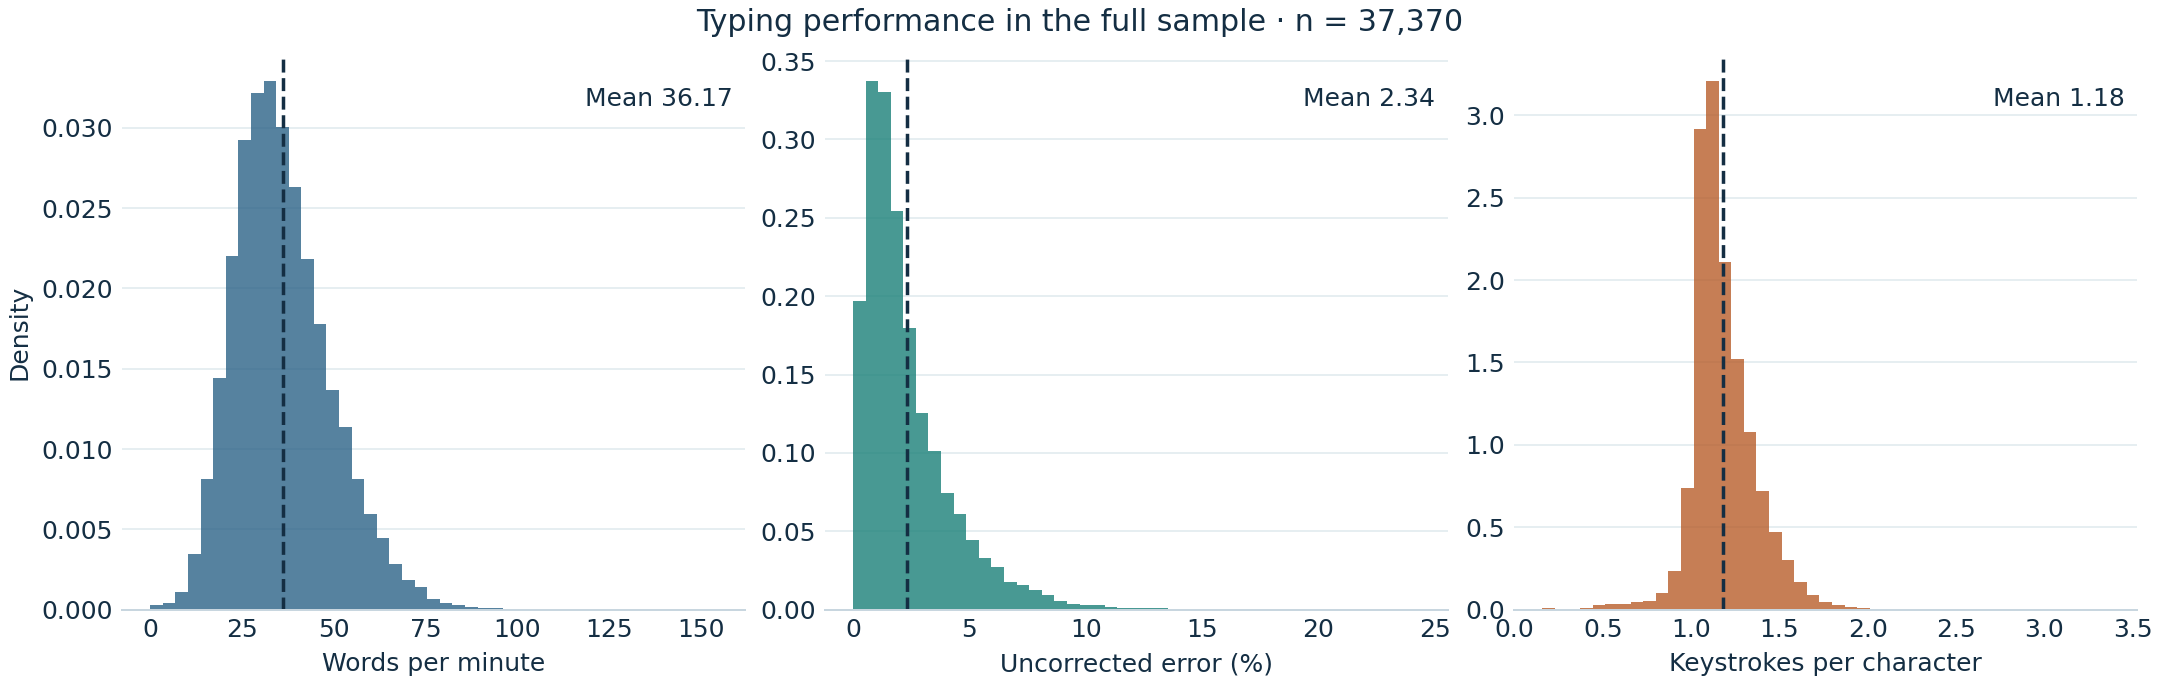

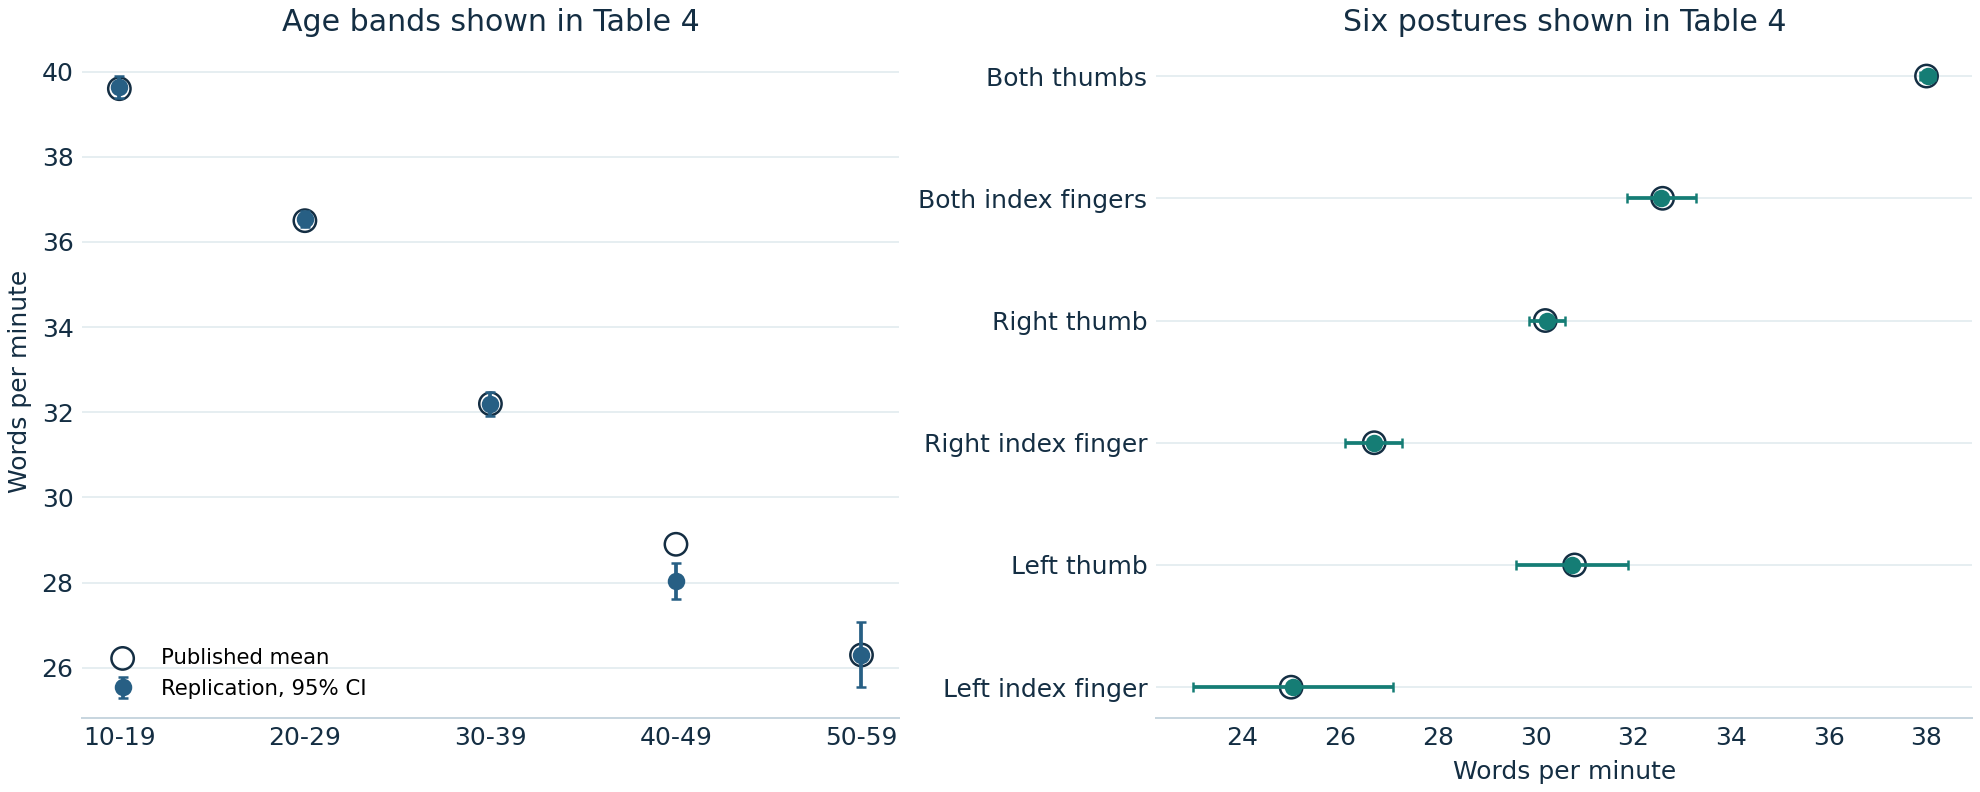

In [12]:
with TemporaryDirectory(prefix="typing37k-notebook-") as tmp:
    fresh = Path(tmp)
    run_replication(participants, sample_audit, fresh)

    checked = []
    for table_path in sorted((fresh / "tables").glob("*.csv")):
        computed = pd.read_csv(table_path)
        saved = pd.read_csv(root / "results" / "tables" / table_path.name)
        pd.testing.assert_frame_equal(computed, saved, rtol=1e-8, atol=1e-10)
        checked.append(table_path.name)

    print(f"{len(checked)} fresh result tables match the saved CSVs within numerical tolerance.")
    for filename in checked:
        print(f"  {filename}")

    display(Image(filename=str(fresh / "figures" / "replication_performance_distributions.png"), width=880))
    display(Image(filename=str(fresh / "figures" / "replication_age_and_posture.png"), width=880))

Seeing age and posture in separate comparisons led to my extension question. Does the two-thumb speed gap change across age bands? [Extension report](docs/extension.md)